In [1]:
import sys
import os
sys.path.append(os.path.abspath('..')) # Permite importar desde src/

import pyomo.environ as pyo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import get_carpentry_data
from src.model import build_stochastic_model, solve_model, calculate_ws, calculate_eev

sns.set_theme(style="whitegrid")
%matplotlib inline

In [2]:
scenarios, probs = get_carpentry_data()

# 1. RP (Recourse Problem - Solución Estocástica)
m_rp = build_stochastic_model(scenarios, probs, alpha=None)
solve_model(m_rp)
rp_value = pyo.value(m_rp.obj)

# 2. WS (Wait-and-See - Sabiendo el futuro)
ws_value = calculate_ws(scenarios, probs)

# 3. EEV (Expected Value solution - Plan con el promedio)
eev_value = calculate_eev(scenarios, probs)

# 4. Métricas
evpi = ws_value - rp_value
vss = rp_value - eev_value

print(f"--- MÉTRICAS DE VALOR DE LA INFORMACIÓN ---")
print(f"RP (Solución Estocástica):  ${rp_value:.2f}")
print(f"WS (Wait-and-See):          ${ws_value:.2f}")
print(f"EEV (Plan con Promedio):    ${eev_value:.2f}")
print(f"-------------------------------------------")
print(f"EVPI (Valor Info Perfecta): ${evpi:.2f}")
print(f"VSS (Valor Sol. Estocástica): ${vss:.2f}")
print(f"EVPI [%]: {evpi/rp_value*100:.2f}%")
print(f"VSS [%]:  {vss/rp_value*100:.2f}%")

--- MÉTRICAS DE VALOR DE LA INFORMACIÓN ---
RP (Solución Estocástica):  $1730.00
WS (Wait-and-See):          $4165.00
EEV (Plan con Promedio):    $1545.00
-------------------------------------------
EVPI (Valor Info Perfecta): $2435.00
VSS (Valor Sol. Estocástica): $185.00
EVPI [%]: 140.75%
VSS [%]:  10.69%


,alpha,Expected_Profit,CVaR,Madera,Acabado,Carpinteria
0,0.05,1730.0,1676.315789,1300.0,540.0,325.0
1,0.15,1686.0,1564.235294,1080.0,540.0,270.0
2,0.30,1686.0,1390.285714,1080.0,540.0,270.0
3,0.50,1230.0,1140.000000,600.0,300.0,150.0
4,0.70,1124.0,1124.000000,520.0,240.0,130.0
5,0.90,1124.0,1124.000000,520.0,240.0,130.0


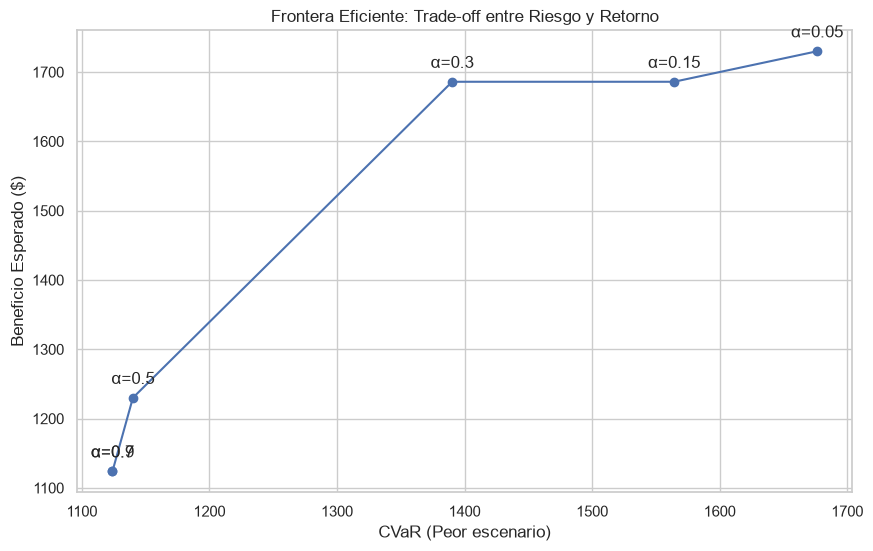

In [3]:
alphas = [0.05, 0.15, 0.3, 0.5, 0.7, 0.9]
resultados = []

for alpha in alphas:
    m = build_stochastic_model(scenarios, probs, alpha=alpha)
    solve_model(m)
    
    expected_profit = sum(probs[w] * pyo.value(m.profit_w[w]) for w in m.W)
    cvar_val = pyo.value(m.obj)
    
    resultados.append({
        'alpha': alpha,
        'Expected_Profit': expected_profit,
        'CVaR': cvar_val,
        'Madera': pyo.value(m.x_l),
        'Acabado': pyo.value(m.x_f),
        'Carpinteria': pyo.value(m.x_p)
    })

df_res = pd.DataFrame(resultados)
display(df_res)

plt.figure(figsize=(10, 6))
plt.plot(df_res['CVaR'], df_res['Expected_Profit'], marker='o', linestyle='-', color='b')
for i, row in df_res.iterrows():
    plt.annotate(f"α={row['alpha']}", (row['CVaR'], row['Expected_Profit']), 
                 textcoords="offset points", xytext=(0,10), ha='center')
plt.xlabel('CVaR (Peor escenario)')
plt.ylabel('Beneficio Esperado ($)')
plt.title('Frontera Eficiente: Trade-off entre Riesgo y Retorno')
plt.grid(True)
plt.show()

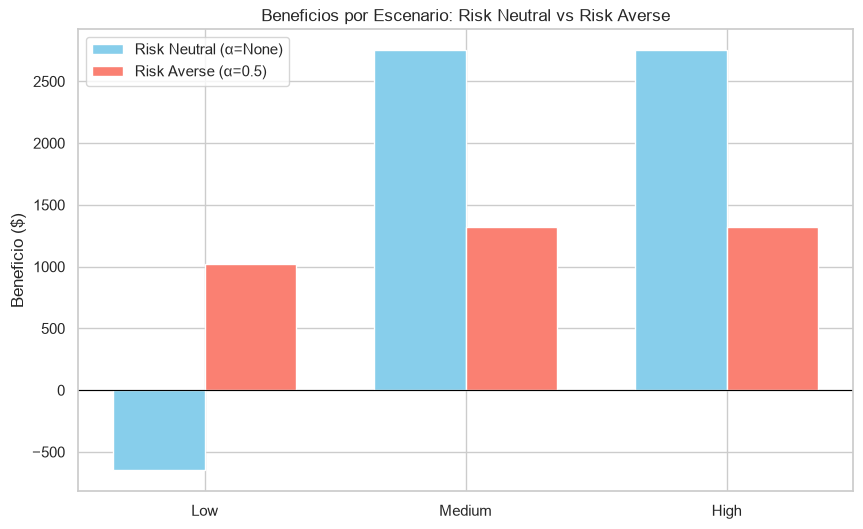

In [4]:
m_rn = build_stochastic_model(scenarios, probs, alpha=None)
solve_model(m_rn)

m_ra = build_stochastic_model(scenarios, probs, alpha=0.5)
solve_model(m_ra)

rn_profits = [pyo.value(m_rn.profit_w[w]) for w in m_rn.W]
ra_profits = [pyo.value(m_ra.profit_w[w]) for w in m_ra.W]

x = np.arange(len(scenarios))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, rn_profits, width, label='Risk Neutral (α=None)', color='skyblue')
ax.bar(x + width/2, ra_profits, width, label='Risk Averse (α=0.5)', color='salmon')

ax.set_ylabel('Beneficio ($)')
ax.set_title('Beneficios por Escenario: Risk Neutral vs Risk Averse')
ax.set_xticks(x)
ax.set_xticklabels(scenarios.keys())
ax.legend()
ax.axhline(0, color='black', linewidth=0.8)
plt.show()